# Session 4 - What does a protein language model know about enzymes?

**AI in Quantitative Biology - optional practical or homework (about 60 min)**

Enzymes are sorted by the reaction they catalyse into six **EC classes** (oxidoreductases,
transferases, hydrolases, lyases, isomerases, ligases). Can a model tell the class from the
sequence?

We compare two ways of turning a protein into numbers, and give both to **the same simple
classifier**:

* **composition**: the fraction of each of the 20 amino acids (and the length). No learning involved.
* **ESM-2** (Lin et al. 2023): a neural network trained on about 65 million protein sequences to guess hidden
  residues from their context, like a language model guessing a missing word. It has never been
  shown an enzyme class, or any other annotation.

Random guessing among six balanced classes is right 17% of the time. **Write down your guess for
the accuracy of each representation.**

| Part | Topic | Time |
|---|---|---|
| 1 | Two representations | 10 min |
| 2 | Same classifier, different input | 15 min |
| 3 | Enzymes from families never seen | 15 min |
| 4 | A scaling law for models | 20 min |

✏️ marks exercises and ❓ questions to discuss with your neighbour: try them yourself first, the solution follows right after.

## Setup

You do **not** run ESM-2 here: its output was computed once (`data_prep/make_esm2_embeddings.py`)
and stored in `data/enzymes_esm2.npz`. The notebook needs only scikit-learn and runs in about a
minute.

In [ ]:
# @title Setup: imports and data folder (run me)
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score

RNG = 0                                         # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)

import os
from pathlib import Path

def find_data_dir():
    "$QBIO_DATA if set, else the `data/` folder of the course repository (here or above)."
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "enzymes_esm2.npz").exists():
            return p / "data"
    raise FileNotFoundError("Cannot find data/: run the notebook inside the course repository, "
                            "or set QBIO_DATA to the path of its data/ folder")

DATA_DIR = find_data_dir()
print("data from", DATA_DIR)

data from /home/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data


## Part 1 - Two representations

The table has 2047 reviewed enzymes from five model organisms, about 350 per class, each with its
**protein family** (a group of evolutionarily related proteins).

In [ ]:
enz = pd.read_csv(DATA_DIR / "enzymes.tsv", sep="\t")
y = enz["ec_name"].values
print(enz.shape, "-", enz["family"].nunique(), "families")
print(enz["ec_name"].value_counts().to_dict())
enz[["protein_name", "organism", "ec_name", "family", "length", "sequence"]].head(3)

(2047, 10) - 1102 families
{'Oxidoreductase': 350, 'Transferase': 350, 'Hydrolase': 350, 'Lyase': 350, 'Isomerase': 350, 'Ligase': 297}


,protein_name,organism,ec_name,family,length,sequence
0,Flavin-containing monooxygenase FMO GS-OX5,Arabidopsis thaliana,Oxidoreductase,FMO family,459,MAPARTRVNSLNVAVIGAGAAGLVAARELRRENHTVVVFERDSKVG...
1,3beta-hydroxysteroid-dehydrogenase/decarboxyla...,Arabidopsis thaliana,Oxidoreductase,3-beta-HSD family,561,MDEDSVHGDSHLKTCVVLGGRGFIGRSLVSRLLRLGNWTVRVADSG...
2,Prolyl 4-hydroxylase 13,Arabidopsis thaliana,Oxidoreductase,P4HA family,274,MRSYGKEKKLVFPYVFIACCFFLAIFGFCFFNLFSQGISFSEIPTT...


In [ ]:
AA = "ACDEFGHIKLMNPQRSTVWY"
composition = np.array([[seq.count(a) / len(seq) for a in AA] for seq in enz["sequence"]])
X_comp = np.column_stack([composition, np.log(enz["length"])])

esm = np.load(DATA_DIR / "enzymes_esm2.npz")
assert (esm["accession"] == enz["accession"].values).all()      # same proteins, same order
X_esm = esm["esm2_8M"].astype(np.float32)

print("composition:", X_comp.shape)
print("ESM-2      :", X_esm.shape)

composition: (2047, 21)
ESM-2      : (2047, 320)


Each protein is now a row of 21 numbers (composition) or of 320 numbers (ESM-2).

How the 320 numbers are made: ESM-2 reads the sequence and produces one vector per residue,
which encodes that residue *in its context*. We average these vectors along the sequence. The
result is called an **embedding**. We use the smallest ESM-2, with 8 million parameters.

The composition columns have a meaning (column 0 is the fraction of alanine). The embedding
columns have none that we know of.

❓ Composition throws away the order of the residues. Does the averaged ESM-2 embedding throw it
away too?

**Answer.** Not entirely. The average is taken *after* the network has read the sequence, so the
vector of each residue already depends on its neighbours and on distant residues. Shuffling the
sequence leaves the composition unchanged and changes the embedding.

## Part 2 - Same classifier, different input

The classifier is a **logistic regression**: a linear model, the classification counterpart of
the straight line of session 1. It is deliberately simple, so that any difference comes from the
representation. Accuracy is measured with 5-fold cross-validation.

In [ ]:
def classifier():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

random_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)

acc_random = {name: cross_val_score(classifier(), X, y, cv=random_cv).mean()
              for name, X in [("composition", X_comp), ("ESM-2 (8M)", X_esm)]}
for name, acc in acc_random.items():
    print(f"{name:12s} accuracy = {acc:.3f}")

composition  accuracy = 0.291
ESM-2 (8M)   accuracy = 0.646


❓ Compare with your guesses. The classifier is the same and the labels are the same. Where does
the difference come from?

**Answer.** Composition reaches 0.29, not far above chance (0.17). The embedding reaches 0.65.
The linear classifier learned nothing more than before: the knowledge was already in the
embedding, put there by a network that only ever played "guess the hidden residue". To play that
game well on millions of proteins, the network had to pick up regularities of protein families,
folds and binding sites, and these are related to function.

This is the idea behind **pretraining**: learn a general representation from a huge amount of
unlabelled data, then solve a specific task with few labelled examples and a simple model.

✏️ **Exercise 2.1.** A representation with 320 columns gives a classifier many more ways to fit
2047 labels by chance. Check that this is not what happens: shuffle the labels and repeat the
cross-validation for both representations.

In [ ]:
y_shuffled = np.random.default_rng(RNG).permutation(y)
for name, X in [("composition", X_comp), ("ESM-2 (8M)", X_esm)]:
    print(f"{name:12s} accuracy with shuffled labels = {cross_val_score(classifier(), X, y_shuffled, cv=random_cv).mean():.3f}")

composition  accuracy with shuffled labels = 0.151


ESM-2 (8M)   accuracy with shuffled labels = 0.154


**Answer.** Both fall to chance (about 0.15). On the *training* data the classifier with 320
columns can fit many shuffled labels, but cross-validation is not fooled. The 0.65 is real.

## Part 3 - Enzymes from families never seen

In session 2, a model that predicted lifespan looked much better when the test species had close
relatives in the training set. Proteins have relatives too. Members of a **family** share an
ancestor, a fold and often the function, so with a random split most test enzymes have a relative
in training and the classifier can recognise the family instead of the chemistry.

`StratifiedGroupKFold` keeps every family entirely in training or entirely in test.

In [ ]:
families = enz["family"].values
family_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG)

acc_family = {name: cross_val_score(classifier(), X, y, cv=family_cv, groups=families).mean()
              for name, X in [("composition", X_comp), ("ESM-2 (8M)", X_esm)]}
pd.DataFrame({"random split": acc_random, "families held out": acc_family}) 

,random split,families held out
composition,0.291,0.270
ESM-2 (8M),0.646,0.531


❓ Which representation loses more? Does the advantage of ESM-2 survive?

**Answer.** Composition barely moves (0.29 to 0.27): it had little to lose. ESM-2 falls from
0.65 to 0.53. Part of its score came from recognising relatives, and embeddings are very good at
that. But most of the gain survives: for enzymes of families absent from training, the embedding
still doubles the accuracy of composition. It carries information about function that
generalises across families.

✏️ **Exercise 3.1.** Replace the logistic regression by a **1-nearest-neighbour** classifier on the
embeddings: each enzyme gets the class of the most similar enzyme in the training set. Compare
the two splits. What does this model do, in biological terms?

In [ ]:
nearest = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))
print(f"1-NN on ESM-2: random split {cross_val_score(nearest, X_esm, y, cv=random_cv).mean():.3f},",
      f"families held out {cross_val_score(nearest, X_esm, y, cv=family_cv, groups=families).mean():.3f}")

1-NN on ESM-2: random split 0.698, families held out 0.541


**Answer.** With a random split, 1-NN reaches 0.70 and beats the logistic regression; with
families held out it falls to 0.54. It is a search for the closest relative and a transfer of
its annotation, which is how most proteins in databases are annotated in practice. It works as
long as a relative exists.

❓ We held the families out of the *classifier*. Were they held out of ESM-2?

**Answer.** No. ESM-2 was trained on essentially all known protein sequences, so it has almost
certainly read these enzymes and their relatives. It never saw their EC class, so no label
leaked. But "a family the model has never seen" is true only for the last, small, linear part of
our pipeline. A protein from a family discovered tomorrow, unlike anything in the databases,
would be a harder test than ours, and we cannot run it with this dataset. As in session 2:
"unseen" has degrees, and a score describes the population it was measured on.

## Part 4 - A scaling law for models

ESM-2 exists in several sizes. The file contains the embeddings of the same enzymes from three of
them:

In [ ]:
sizes = {"8M": 8e6, "35M": 35e6, "150M": 150e6}             # number of parameters
rows = []
for name, n_params in sizes.items():
    X = esm[f"esm2_{name}"].astype(np.float32)
    rows.append({"model": f"ESM-2 {name}", "parameters": n_params, "embedding size": X.shape[1],
                 "random split": cross_val_score(classifier(), X, y, cv=random_cv).mean(),
                 "families held out": cross_val_score(classifier(), X, y, cv=family_cv, groups=families).mean()})
scaling = pd.DataFrame(rows).set_index("model")
scaling

,parameters,embedding size,random split,families held out
model,,,,
ESM-2 8M,8.000e+06,320,0.646,0.531
ESM-2 35M,3.500e+07,480,0.755,0.612
ESM-2 150M,1.500e+08,640,0.774,0.613


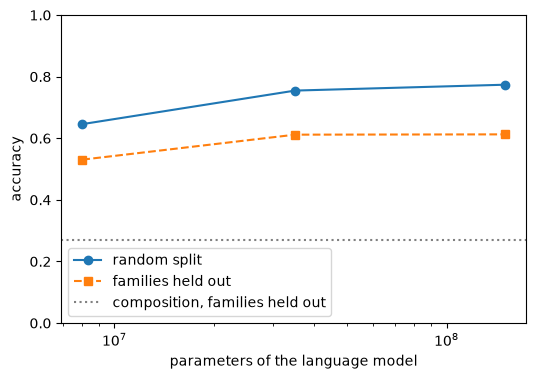

In [ ]:
plt.figure(figsize=(6, 4))
for col, style in [("random split", "o-"), ("families held out", "s--")]:
    plt.plot(scaling["parameters"], scaling[col], style, label=col)
plt.axhline(acc_family["composition"], color="grey", ls=":", label="composition, families held out")
plt.xscale("log"); plt.ylim(0, 1)
plt.xlabel("parameters of the language model"); plt.ylabel("accuracy"); plt.legend();

❓ Does a bigger language model give a better representation? If you had only the first two points, what would you have predicted for the third?

**Answer.** From 8 to 35 million parameters, yes: accuracy rises from 0.65 to 0.76 with a random split and from 0.53 to 0.61 with families held out. From 35 to 150 million it barely moves (0.77 and 0.61). Two points suggest a trend and the third one breaks it: on this task, with this classifier, the curve flattens. This is session 2 again. A line through the first two points would have extrapolated to a gain that is not there.

Why it flattens is an open question that this notebook cannot settle. The limit may be our 2047 enzymes and the linear classifier, the averaging over the sequence, or the task itself: EC classes group reactions that evolution invented many times in unrelated proteins.

✏️ **Exercise 4.1.** Bigger models also produce longer embeddings (320, 480, 640 numbers). Maybe
the classifier simply benefits from more columns. Design a control and run it. *Hint:* `PCA` can
compress every embedding to the same number of columns.

In [ ]:
from sklearn.decomposition import PCA

for name in sizes:
    X = esm[f"esm2_{name}"].astype(np.float32)
    same_size = make_pipeline(StandardScaler(), PCA(n_components=100, random_state=RNG), LogisticRegression(max_iter=2000))
    print(f"ESM-2 {name:5s} compressed to 100 columns: families held out =",
          f"{cross_val_score(same_size, X, y, cv=family_cv, groups=families).mean():.3f}")

ESM-2 8M    compressed to 100 columns: families held out = 0.534


ESM-2 35M   compressed to 100 columns: families held out = 0.567


ESM-2 150M  compressed to 100 columns: families held out = 0.537


**Answer.** With every embedding compressed to 100 columns, the accuracies with families held out are 0.53, 0.57 and 0.54. The middle model is still the best, by less, and the largest one loses its advantage over the smallest. So part of what looked like "a better model" was "a longer vector". Which model is best depends on a detail of the analysis, which is a sign that the differences between the two larger models are not solid.

## Summary

* With the same linear classifier, replacing amino-acid composition by the embedding of a small
  protein language model raises the accuracy from 0.29 to 0.65. The knowledge comes from
  **pretraining** on unlabelled sequences.
* Holding out families costs the embedding more (0.65 to 0.53) than composition, but most of the
  gain survives.
* The language model itself has seen everything. A held-out family is unseen by our classifier,
  not by ESM-2.
* **Bigger is not automatically better.** Going from 8 to 35 million parameters helps; going to 150 million does not, on this task. Three points are not a law.

## References and data sources

**Data**

* Enzyme and targeting tables: reviewed entries of UniProtKB/Swiss-Prot (UniProt Consortium 2023), downloaded with the UniProt REST API on 2026-11-10 from human, *E. coli* K-12, yeast, *Arabidopsis* and *B. subtilis*; Swiss-Prot changes at every release, so the committed TSVs are the reference. See `course/README.md` and `data_prep/`. `enzymes_esm2.npz`: mean-pooled ESM-2 embeddings of the same proteins, computed with `data_prep/make_esm2_embeddings.py`.

**Further reading**

* Lin Z, Akin H, Rao R, et al. (2023). Evolutionary-scale prediction of atomic-level protein structure with a language model. *Science* 379:1123–1130. [doi:10.1126/science.ade2574](https://doi.org/10.1126/science.ade2574) — ESM-2
* Rives A, Meier J, Sercu T, et al. (2021). Biological structure and function emerge from scaling unsupervised learning to 250 million protein sequences. *PNAS* 118:e2016239118. [doi:10.1073/pnas.2016239118](https://doi.org/10.1073/pnas.2016239118) — the ESM-1b model that preceded it
* Yu T, Cui H, Li JC, et al. (2023). Enzyme function prediction using contrastive learning. *Science* 379:1358–1363. [doi:10.1126/science.adf2465](https://doi.org/10.1126/science.adf2465) — a contrastive-learning EC predictor, for comparison
* Kapoor S, Narayanan A (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns* 4:100804. [doi:10.1016/j.patter.2023.100804](https://doi.org/10.1016/j.patter.2023.100804) — a taxonomy of data leakage